righe CSV 2013–2025         276679.00
missioni 2013–2025           56732.00
somma in euro 2013–2025   22879177.36
Name: Controlli, dtype: float64

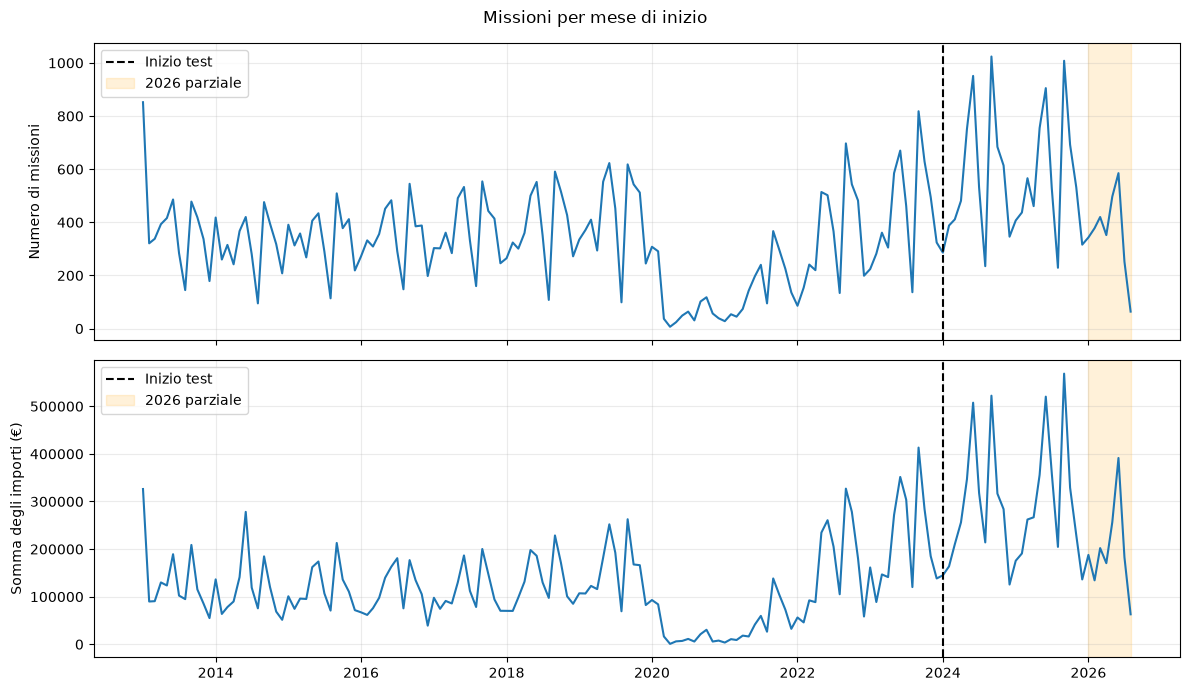

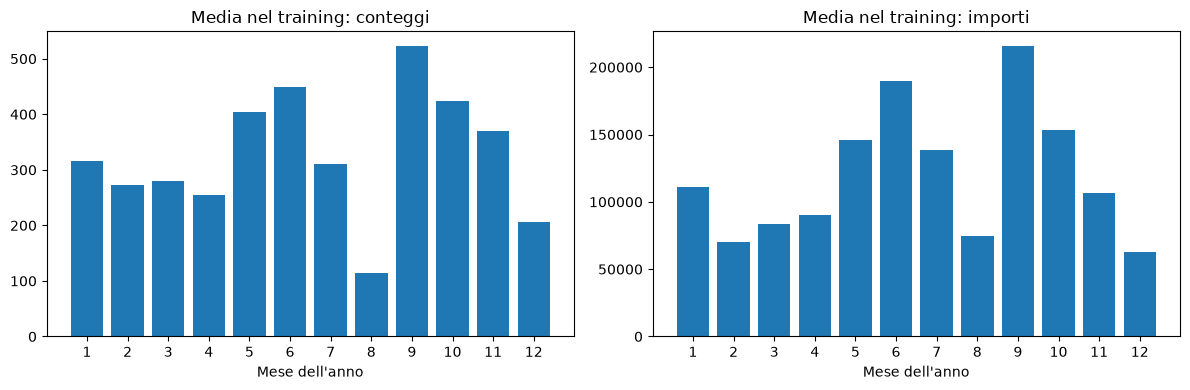

In [111]:
%run ./01_dati.ipynb

In [112]:
dati = dati_conteggi
previsioni_conteggi = {"Stagionale": dati["stagionale_test"].copy()}

# Ogni riga è un'afferenza in un mese
#display(pd.DataFrame({
#    "mese": test["mese"].head(),
#    "afferenza": test["afferenza"].head(),
#    "conteggio_reale": dati["reali_test"][:5],
#    "previsione_stagionale": previsioni_conteggi["Stagionale"][:5],
#}))


### Regressione lineare


In [113]:
def regressione_lineare(dati):
    # I primi 12 valori sono standardizzati
    x_train = dati["X_train"].double()
    x_test = dati["X_test"].double()
    # y_train era (N_train,): si trasforma in una colonna (N_train, 1).
    # E' già standardizzata quindi anche le previsioni saranno standardizzate.
    y_train = dati["y_train"].double().reshape(-1, 1)

    # Concateno la colonna di 1 con dim=1
    x_train = torch.cat([torch.ones(len(x_train), 1, dtype=torch.float64), x_train], dim=1)
    x_test = torch.cat([torch.ones(len(x_test), 1, dtype=torch.float64), x_test], dim=1)

    beta_lstsq = torch.linalg.lstsq(x_train, y_train, driver="gelsd").solution
    # squeeze(1) toglie solo la colonna singola, rimane un valore per riga.
    pred_normalizzate = (x_test @ beta_lstsq).squeeze(1).numpy()

    # Ritorna all'unità originale: n missioni oppure euro.
    previsioni = pred_normalizzate * dati["std"] + dati["media"]
    # Parametri imparati, array delle previsioni.
    return beta_lstsq, previsioni

pesi_conteggi, pred_lineare = regressione_lineare(dati)
previsioni_conteggi["Lineare"] = pred_lineare
#print("Shape:", tuple(pesi_conteggi.shape))


### MLP

In [114]:
class MissioniDataset(Dataset):
    def __init__(self, x, y):
        self.x = x  # Tutti gli ingressi di training.
        self.y = y  # Tutte le risposte.

    def __len__(self):
        return len(self.y)

    def __getitem__(self, indice):
        return self.x[indice], self.y[indice]

# Il loader non ha accesso al test.
dataset_conteggi = MissioniDataset(dati["X_train"], dati["y_train"])
loader_conteggi = DataLoader(
    dataset_conteggi,  
    batch_size=config["batch_size"],
    shuffle=True,
    num_workers=0,
)

#x_batch, y_batch = next(iter(loader_conteggi))
#print("Ingressi di un batch:", tuple(x_batch.shape))
#print("Risposte di un batch:", tuple(y_batch.shape))


In [115]:
#MLP con un hidden layer, caratterizzato da num_hidden neuroni
class MLP(nn.Module):
    def __init__(self, num_ingressi, num_hidden):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(num_ingressi, num_hidden),
            nn.ReLU(),           
            nn.Linear(num_hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(1)

    
def addestra(model, loader):
    model = model.to(device)
    # La rete produce una previsione: previsione e y di shape (B,)
    # La MSE calcola B errori quadratici e ne fa la media: loss è un solo numero per ogni batch
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    storia_loss = []

    for epoca in range(config["epochs"]):
        model.train()
        somma_loss = 0.0
        numero_esempi = 0

        # Il loader restituisce un batch alla volta
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()  
            previsione = model(x)  
            loss = loss_fn(previsione, y)  
            loss.backward() 
            optimizer.step() 

            somma_loss += loss.item() * len(y)
            numero_esempi += len(y)

        storia_loss.append(somma_loss / numero_esempi)
        if (epoca + 1) % 5 == 0:
            print(f"Epoca {epoca + 1}: MSE training = {storia_loss[-1]:.4f}")

    # 2 risultati: la rete con i pesi aggiornati e una loss per ogni epoca
    return model, storia_loss


torch.manual_seed(config["seed"])
# shape[1] legge il numero di colonne F, non il numero di finestre.
mlp_conteggi = MLP(dati["X_train"].shape[1], config["hidden_dim"])
mlp_conteggi, loss_mlp_conteggi = addestra(mlp_conteggi, loader_conteggi)

def prevedi(model, dati):
    with torch.no_grad():
        # Una risposta standardizzata per ciascuna riga di X_test
        normalizzate = model(dati["X_test"].to(device)).cpu().numpy()
    # Operazione inversa di (valore - media) / std, ritorna il valore originale in numero di missioni o euro
    return normalizzate * dati["std"] + dati["media"]

previsioni_conteggi["MLP"] = prevedi(mlp_conteggi, dati)

Epoca 5: MSE training = 0.2503
Epoca 10: MSE training = 0.2009
Epoca 15: MSE training = 0.1786
Epoca 20: MSE training = 0.1673
Epoca 25: MSE training = 0.1596
Epoca 30: MSE training = 0.1537
Epoca 35: MSE training = 0.1502
Epoca 40: MSE training = 0.1443


### Errori

In [116]:
def tabella_previsioni(previsioni, dati, target):
    # Lista contenente una tabella per ciascun modello.
    parti = []
    # items() restituisce coppie (nome del modello, array delle sue previsioni).
    for nome, valori in previsioni.items():
        assert len(valori) == len(test)
        assert np.isfinite(valori).all()

        tabella = test[["afferenza", "mese"]].copy()
        tabella["modello"] = nome
        # Valori reali nelle unità originali, non y_test standardizzata
        tabella["reale"] = dati["reali_test"]
        # Previsioni originali
        tabella["previsto_originale"] = valori
        tabella["previsto"] = np.maximum(valori, 0) if target == "conteggi" else valori
        parti.append(tabella)
    return pd.concat(parti, ignore_index=True)

def errori(tabella, raggruppa):
    # Una riga per ciascun gruppo: modello, afferenza, anno o mese.
    tabella2 = tabella.copy()
    differenza = tabella2["previsto"] - tabella2["reale"]
    tabella2["errore_assoluto"] = differenza.abs()
    tabella2["errore_quadrato"] = differenza ** 2
    # Raggruppa è una lista di nomi di colonne, agg calcola una sintesi per gruppo.
    risultato = tabella2.groupby(raggruppa).agg(
        # N è il numero di righe/previsioni confrontate
        N=("reale", "size"),
        MAE=("errore_assoluto", "mean"),
        MSE=("errore_quadrato", "mean"),
    )
    # pop estrae e toglie MSE, sqrt la trasforma in RMSE
    risultato["RMSE"] = np.sqrt(risultato.pop("MSE"))
    return risultato

risultati_conteggi = tabella_previsioni(previsioni_conteggi, dati, "conteggi")
#display(risultati_conteggi.head())


### Confronto il numero di missioni

CONTEGGI — Test gennaio 2024–agosto 2026
1. Mediamente quanto sbaglia il modello per una singola afferenza in un singolo mese?


,N,MAE,RMSE
modello,,,
Lineare,1088,5.28,10.06
MLP,1088,4.68,8.64
Stagionale,1088,5.81,10.64


1b. Dettaglio per anno (2026 parziale fino ad agosto)


1c. Errori per afferenza, gennaio 2024–agosto 2026


1d. MAE per mese, gennaio 2024–agosto 2026


modello,Lineare,MLP,Stagionale
mese_anno,,,
1,3.50,3.18,3.79
2,3.79,3.97,4.54
3,4.53,4.39,5.19
4,3.73,3.61,5.21
5,6.59,5.54,8.16
6,8.36,6.95,8.59
7,4.93,5.48,7.06
8,3.30,2.55,3.74
9,11.76,7.80,8.66


2. Confronto su totale complessivo mensile di tutte le afferenze
Per ogni modello vengono sommate tutte le afferenze dello stesso mese, dopo si calcolano MAE e RMSE sui totali mensili - gennaio 2024–agosto 2026


,N,MAE,RMSE
modello,,,
Lineare,32,87.55,107.46
MLP,32,66.72,87.10
Stagionale,32,102.09,132.83


2b. Dettaglio per anno degli errori sui totali mensili


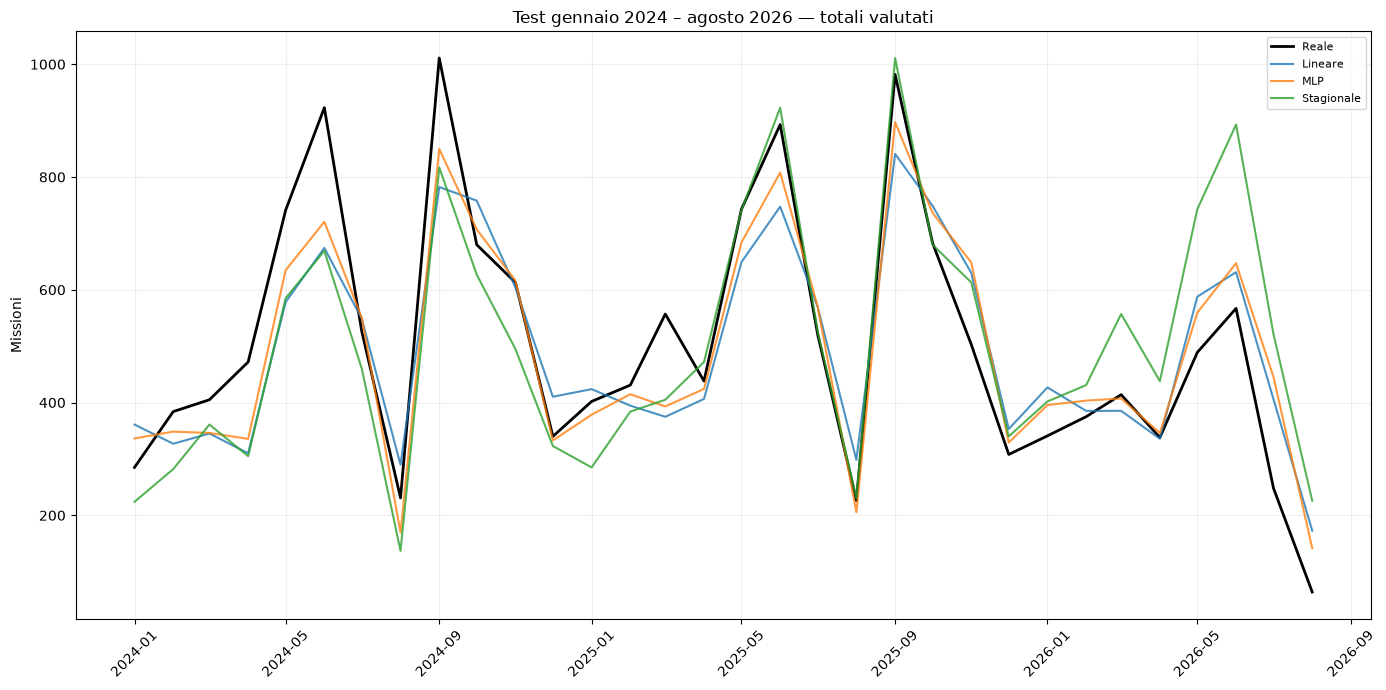

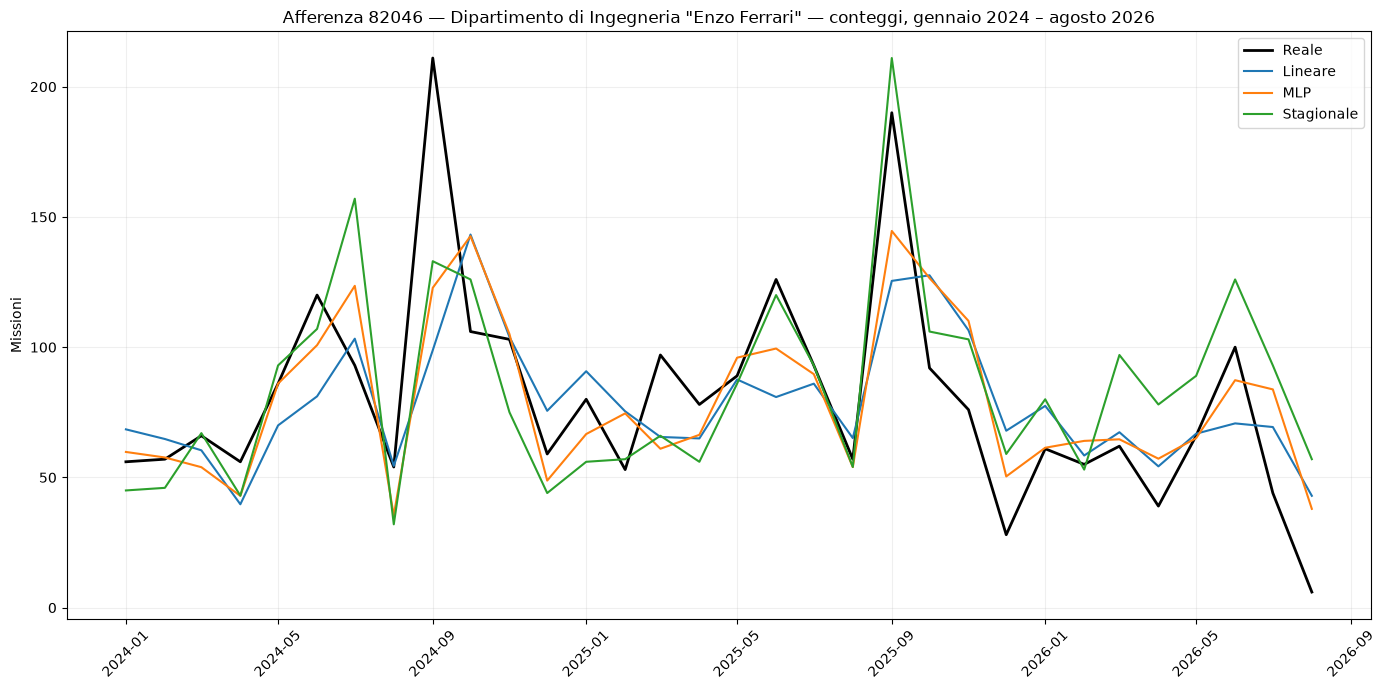

In [117]:
def stile_metriche(tabella, livello_gruppo=None):
    # Restituisce una tabella
    def grassetto_minimi(dati):
        # Per ogni cella, se è il minimo di quella metrica, mettiamo il grassetto.
        stili = pd.DataFrame("", index=dati.index, columns=dati.columns)
        # Senza livello confrontiamo tutti i modelli; con un livello li confrontiamo separatamente, per esempio all'interno dello stesso anno o afferenza.
        gruppi = [dati] if livello_gruppo is None else [
            gruppo for _, gruppo in dati.groupby(level=livello_gruppo, sort=False)
        ]
        for gruppo in gruppi:
            for metrica in ["MAE", "RMSE"]:
                minimo = gruppo[metrica].min()
                for indice in gruppo.index[gruppo[metrica].eq(minimo)]:
                    stili.loc[indice, metrica] = "font-weight: bold"
        return stili

    formati = {"N": "{:.0f}", "MAE": "{:.2f}", "RMSE": "{:.2f}"}
    # na_rep mostra i valori mancanti della riga finale come tre puntini.
    return tabella.style.format(formati, na_rep="...").apply(
        grassetto_minimi, axis=None
    )


def mostra_confronto(risultati, target):
    confronto = risultati.copy()
    confronto["anno"] = confronto["mese"].dt.year
    confronto["mese_anno"] = confronto["mese"].dt.month

    # 1. Mediamente quanto sbaglia il modello per una singola afferenza in un singolo mese?
    # L'errore viene calcolato per ogni coppia afferenza-mese, poi mediato sui 32 mesi.
    print(f"{target.upper()} — Test gennaio 2024–agosto 2026")
    print("1. Mediamente quanto sbaglia il modello per una singola afferenza in un singolo mese?")
    metriche = errori(confronto, ["modello"])
    display(stile_metriche(metriche))

    # 1b. Una riga per ciascuna combinazione anno/modello
    print("1b. Dettaglio per anno (2026 parziale fino ad agosto)")
    metriche_anno = errori(confronto, ["anno", "modello"])
    display(stile_metriche(metriche_anno, livello_gruppo="anno"))

    # 1c. Errori per afferenza
    print("1c. Errori per afferenza, gennaio 2024–agosto 2026")
    metriche_afferenza = errori(confronto, ["afferenza", "modello"])
    afferenze_mostrate = ["82046", "82053", "82044"]
    # IndexSlice seleziona i tre codici e tutti i modelli, nell'ordine indicato.
    metriche_afferenza = metriche_afferenza.loc[
        pd.IndexSlice[afferenze_mostrate, :], :
    ]
    # Sostituisce i codici con le descrizioni
    denominazioni_brevi = {
        codice: denominazione[:29].rstrip() + "..."
        for codice, denominazione in DENOMINAZIONE_DA_CODICE.items()
    }
    metriche_afferenza = metriche_afferenza.rename(
        index=denominazioni_brevi, level="afferenza"
    )
    indice_puntini = pd.MultiIndex.from_tuples(
        [("...", "")], names=metriche_afferenza.index.names
    )
    riga_puntini = pd.DataFrame(
        [[np.nan, np.nan, np.nan]],
        index=indice_puntini,
        columns=metriche_afferenza.columns,
    )
    metriche_afferenza = pd.concat([metriche_afferenza, riga_puntini])
    display(stile_metriche(metriche_afferenza, livello_gruppo="afferenza"))

    print("1d. MAE per mese, gennaio 2024–agosto 2026")
    # Selezioniamo la colonna MAE e spostiamo il livello modello nelle colonne.
    mae_mese = errori(confronto, ["mese_anno", "modello"])["MAE"].unstack()
    # axis=1 confronta i modelli sulla stessa riga, cioè nello stesso mese.
    display(
        mae_mese.style.format("{:.2f}").highlight_min(
            axis=1, props="font-weight: bold"
        )
    )


    # --- Confronto sui totali mensili di tutte le afferenze ---
    #
    # Quanto sbaglia il modello nel prevedere il totale complessivo mensile di tutte le afferenze?
    # Per ogni modello vengono sommate tutte le afferenze dello stesso mese, dopo si calcolano MAE e RMSE sui totali mensili.
    print("2. Confronto su totale complessivo mensile di tutte le afferenze")
    totali_previsti = risultati.groupby(["modello", "mese"])[["reale", "previsto"]].sum().reset_index()
    totali_previsti["anno"] = totali_previsti["mese"].dt.year
    print("Per ogni modello vengono sommate tutte le afferenze dello stesso mese, dopo si calcolano MAE e RMSE sui totali mensili - gennaio 2024–agosto 2026")
    metriche_totali = errori(totali_previsti, ["modello"])
    display(stile_metriche(metriche_totali))

    print("2b. Dettaglio per anno degli errori sui totali mensili")
    metriche_totali_anno = errori(totali_previsti, ["anno", "modello"])
    display(stile_metriche(metriche_totali_anno, livello_gruppo="anno"))


    # Grafico per il periodo di test
    unita = "Missioni" if target == "conteggi" else "Euro"
    fig, asse = plt.subplots(figsize=(14, 7))
    # Tutti i mesi disponibili del test, compreso il 2026 parziale.
    periodo = totali_previsti.loc[
        totali_previsti["mese"].between("2024-01-01", fine_test)
    ]
    # I valori reali si ripetono per ciascun modello: li prendo una sola volta.
    # Disegniamo la colonna reale
    reali = periodo.loc[periodo["modello"] == "Stagionale"]
    asse.plot(reali["mese"], reali["reale"], color="black", linewidth=2, label="Reale")
    # Ogni gruppo contiene tutti i mesi previsti da uno stesso modello.
    for nome, gruppo in periodo.groupby("modello"):
        asse.plot(gruppo["mese"], gruppo["previsto"], label=nome, alpha=0.8)
    asse.set_title("Test gennaio 2024 – agosto 2026 — totali valutati")
    asse.set_ylabel(unita)
    asse.tick_params(axis="x", rotation=45)
    asse.grid(alpha=0.2)
    asse.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    # Afferenza di esempio
    codice = "82046"
    esempio = risultati.loc[risultati["afferenza"] == codice].copy()
    fig, asse = plt.subplots(figsize=(14, 7))
    reali = esempio.loc[esempio["modello"] == "Stagionale"]
    asse.plot(reali["mese"], reali["reale"], color="black", linewidth=2, label="Reale")
    for nome, gruppo in esempio.groupby("modello"):
        asse.plot(gruppo["mese"], gruppo["previsto"], label=nome)
    asse.set_title(
        f"Afferenza {etichetta_uo(codice)} — {target}, gennaio 2024 – agosto 2026"
    )
    asse.set_ylabel(unita)
    asse.tick_params(axis="x", rotation=45)
    asse.grid(alpha=0.2)
    asse.legend()
    plt.tight_layout()
    plt.show()
    return metriche

metriche_conteggi = mostra_confronto(risultati_conteggi, "conteggi")


### Importi

Somma in euro delle missioni iniziate nel mese

In [118]:
# Importi
dati = dati_importi
# Stagionale: copia l'importo dello stesso mese dell'anno precedente.
previsioni_importi = {"Stagionale": dati["stagionale_test"].copy()}

# Regressione lineare
pesi_importi, pred_lineare = regressione_lineare(dati)
previsioni_importi["Lineare"] = pred_lineare

In [119]:
dataset_importi = MissioniDataset(dati["X_train"], dati["y_train"])
loader_importi = DataLoader(
    dataset_importi,
    batch_size=config["batch_size"],
    shuffle=True,
    num_workers=0,
)

# MLP con importi
torch.manual_seed(config["seed"])
mlp_importi = MLP(dati["X_train"].shape[1], config["hidden_dim"])
mlp_importi, loss_mlp_importi = addestra(mlp_importi, loader_importi)
previsioni_importi["MLP"] = prevedi(mlp_importi, dati)

Epoca 5: MSE training = 0.3725
Epoca 10: MSE training = 0.3288
Epoca 15: MSE training = 0.3054
Epoca 20: MSE training = 0.2943
Epoca 25: MSE training = 0.2829
Epoca 30: MSE training = 0.2760
Epoca 35: MSE training = 0.2705
Epoca 40: MSE training = 0.2655


### Confronto importi

IMPORTI — Test gennaio 2024–agosto 2026
1. Mediamente quanto sbaglia il modello per una singola afferenza in un singolo mese?


,N,MAE,RMSE
modello,,,
Lineare,1088,3571.12,6809.84
MLP,1088,3141.58,6248.22
Stagionale,1088,3711.39,7303.17


1b. Dettaglio per anno (2026 parziale fino ad agosto)


1c. Errori per afferenza, gennaio 2024–agosto 2026


1d. MAE per mese, gennaio 2024–agosto 2026


modello,Lineare,MLP,Stagionale
mese_anno,,,
1,2530.94,2209.14,2359.64
2,2367.34,1962.26,2586.20
3,2881.77,2895.90,3548.23
4,2691.83,2828.34,3916.92
5,3620.60,3037.12,3162.44
6,5419.33,4078.54,5227.00
7,3897.47,4395.24,5590.89
8,3572.50,2839.03,3438.95
9,7097.82,5771.90,4823.85


2. Confronto su totale complessivo mensile di tutte le afferenze
Per ogni modello vengono sommate tutte le afferenze dello stesso mese, dopo si calcolano MAE e RMSE sui totali mensili - gennaio 2024–agosto 2026


,N,MAE,RMSE
modello,,,
Lineare,32,51244.87,64577.33
MLP,32,45434.12,56095.66
Stagionale,32,58429.85,74494.42


2b. Dettaglio per anno degli errori sui totali mensili


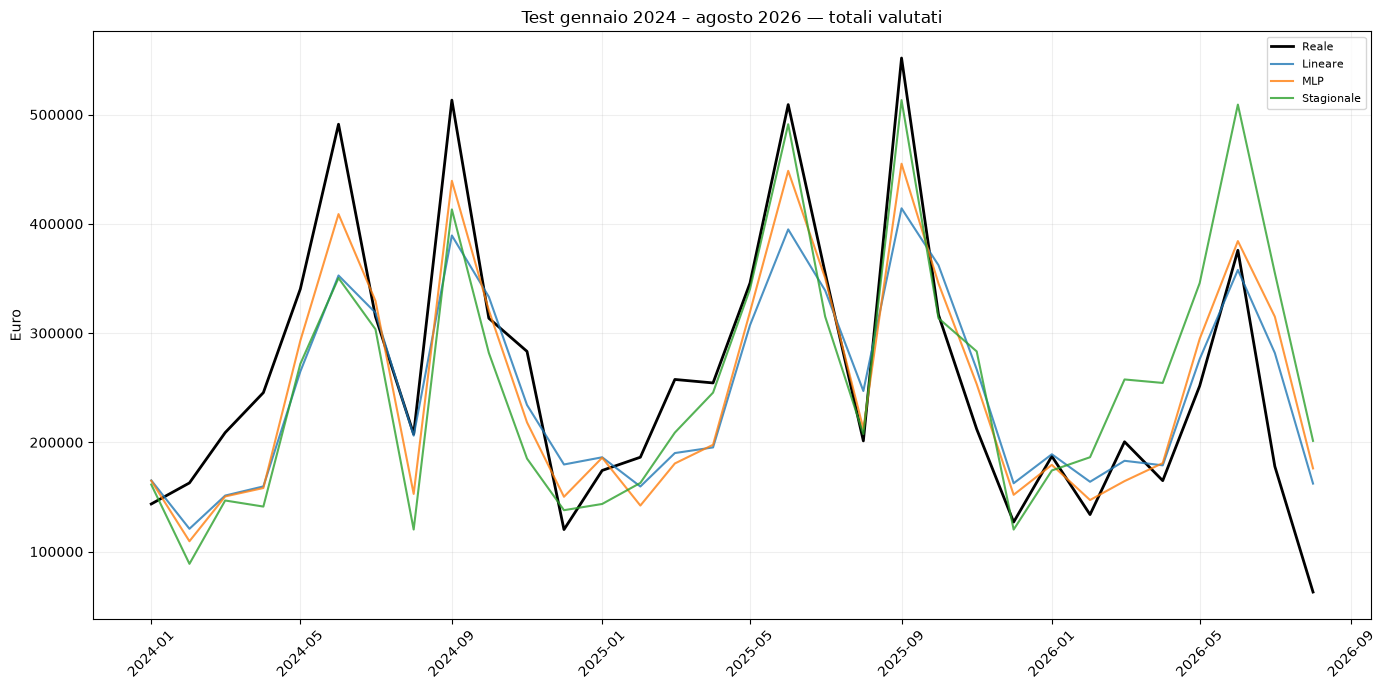

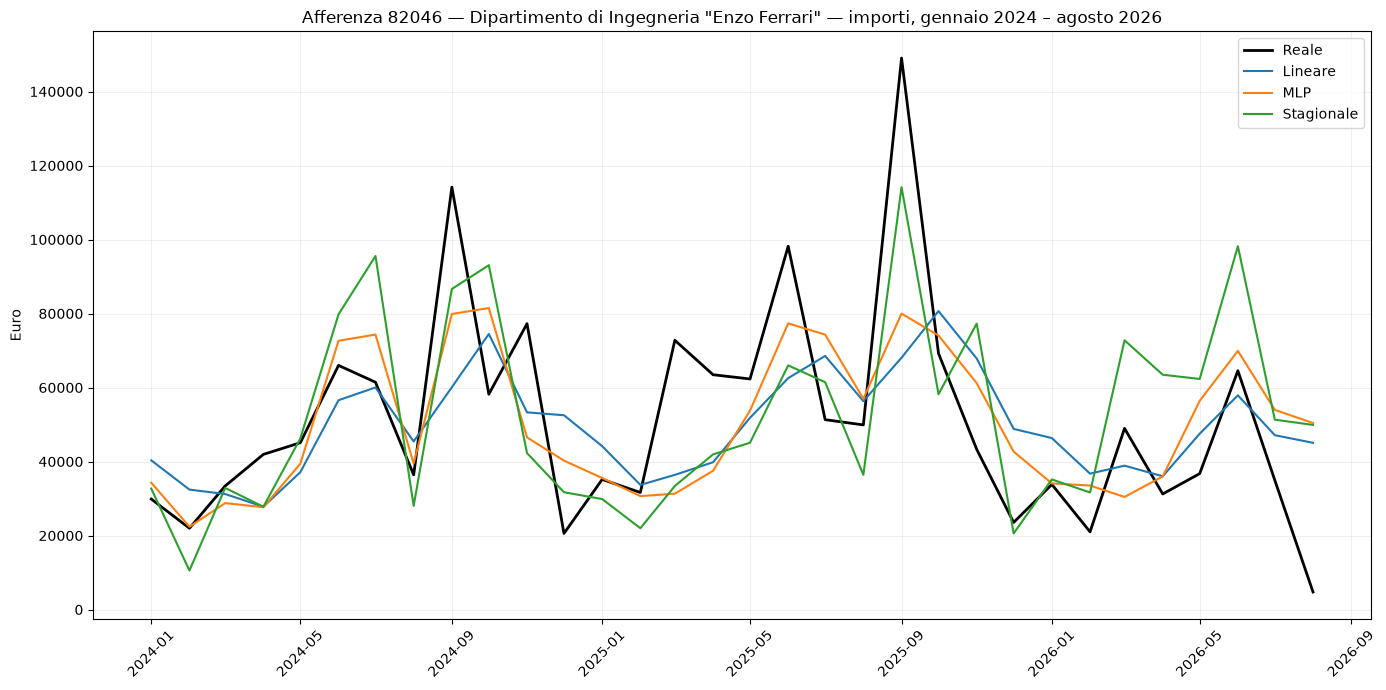

In [120]:
risultati_importi = tabella_previsioni(previsioni_importi, dati, "importi")
# MAE/RMSE sono in euro
metriche_importi = mostra_confronto(risultati_importi, "importi")